In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv('ecommerce_customer_churn.csv')


In [3]:
df.shape

(5630, 19)

In [4]:
 df.isnull().sum()


CustomerID                       0
Churn                            0
Tenure                         281
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                225
PreferredPaymentMethod           0
Gender                           0
HourSpentOnApp                   0
NumberOfDeviceRegistered         0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromLastYear      0
CouponUsed                       0
OrderCount                       0
DaySinceLastOrder              281
CashbackAmount                   0
dtype: int64

There are three specific columns with missing values:
• Tenure: 281 missing rows
• WarehouseToHome: 225 missing rows
• DaySinceLastOrder: 281 missing rows


In [5]:
tenure_median = df['Tenure'].median()
warehouse_median = df['WarehouseToHome'].median()
days_median = df['DaySinceLastOrder'].median()


df['Tenure'] = df['Tenure'].fillna(tenure_median)
df['WarehouseToHome'] = df['WarehouseToHome'].fillna(warehouse_median)
df['DaySinceLastOrder'] = df['DaySinceLastOrder'].fillna(days_median)


print("--- Check for Missing Values After Imputation ---")
print(df[['Tenure', 'WarehouseToHome', 'DaySinceLastOrder']].isnull().sum())

--- Check for Missing Values After Imputation ---
Tenure               0
WarehouseToHome      0
DaySinceLastOrder    0
dtype: int64


In [6]:
 df.duplicated().sum()

np.int64(0)

Our data cleaning pipeline has successfully resolved all structural anomalies:

Missing Value Imputation Handled `Tenure`, `WarehouseToHome`, and `DaySinceLastOrder` missing rows by replacing empty data slots with their respective column medians to protect the cohort against distribution outliers.
Duplicate Record Audit: Verified that 0 duplicated rows exist across the 5,630-user data frame, ensuring each user profile represents a distinct, unique customer history.

The dataset is now clean, complete, and mathematically optimized for Exploratory Data Analysis.

In [10]:
df['Churn'].value_counts()

Churn
0    4582
1    1048
Name: count, dtype: int64

In [8]:
df['Churn'].value_counts(normalize=True) * 100

Churn
0    81.385435
1    18.614565
Name: proportion, dtype: float64

• 4,582 customers stayed (0)
• 1,048 customers left (1)
• This gives a exact baseline global churn rate of 18.61%.


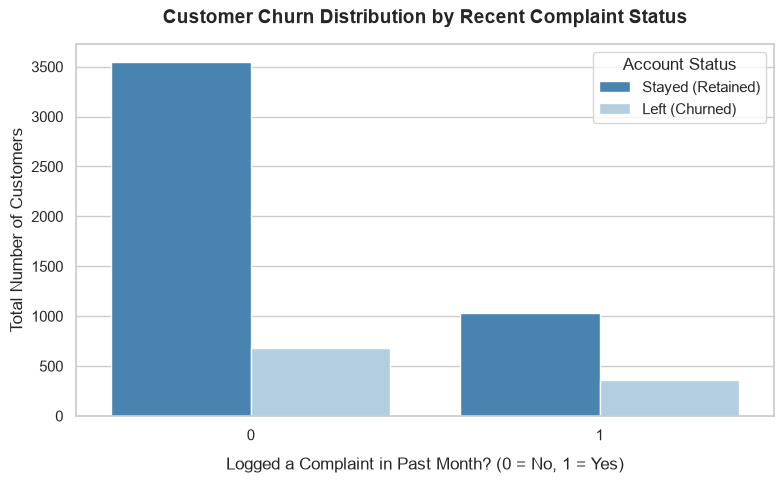

In [7]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Complain', hue='Churn', palette='Blues_r')

plt.title('Customer Churn Distribution by Recent Complaint Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Logged a Complaint in Past Month? (0 = No, 1 = Yes)', fontsize=12, labelpad=10)
plt.ylabel('Total Number of Customers', fontsize=12)
plt.legend(title='Account Status', labels=['Stayed (Retained)', 'Left (Churned)'])

plt.tight_layout()
plt.show()

In [11]:
pd.crosstab(df['Complain'], df['Churn'], normalize='index') * 100

Churn,0,1
Complain,,
0,83.864871,16.135129
1,73.872584,26.127416


• Row 0 (No Complaint): Only 16.13% of these customers churned.
• Row 1 (Logged a Complaint): A staggering 26.12% of these customers churned!
This means customers who file a complaint are significantly more likely to abandon the platform. 


C:\Users\Umar\AppData\Local\Temp\ipykernel_3768\797534482.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='WarehouseToHome', palette='Blues')


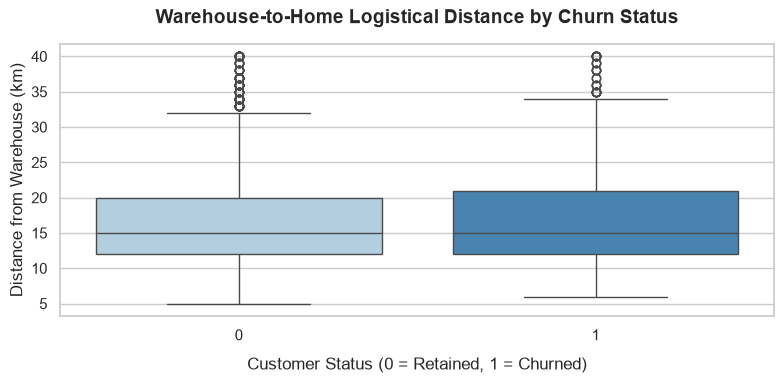

In [12]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df, x='Churn', y='WarehouseToHome', palette='Blues')


plt.title('Warehouse-to-Home Logistical Distance by Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Customer Status (0 = Retained, 1 = Churned)', fontsize=12, labelpad=10)
plt.ylabel('Distance from Warehouse (km)', fontsize=12)

plt.tight_layout()
plt.show()

In [13]:
df.groupby('Churn')['WarehouseToHome'].median()

Churn
0    15.0
1    15.0
Name: WarehouseToHome, dtype: float64

In [14]:
df.groupby('Churn')['WarehouseToHome'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
0,4582.0,16.336971,6.498093,5.0,12.0,15.0,20.0,40.0
1,1048.0,17.204198,7.124242,6.0,12.0,15.0,21.0,40.0


Retained Customers (0): Average warehouse distance is 16.3 km, with 75% living within 20 km.
* Churned Customers (1): Average warehouse distance increases to 17.2 km, with the 75th percentile pushing out further to 21 km.
This indicates that customers located further away from fulfillment centers show a slightly higher tendency to CHURN.

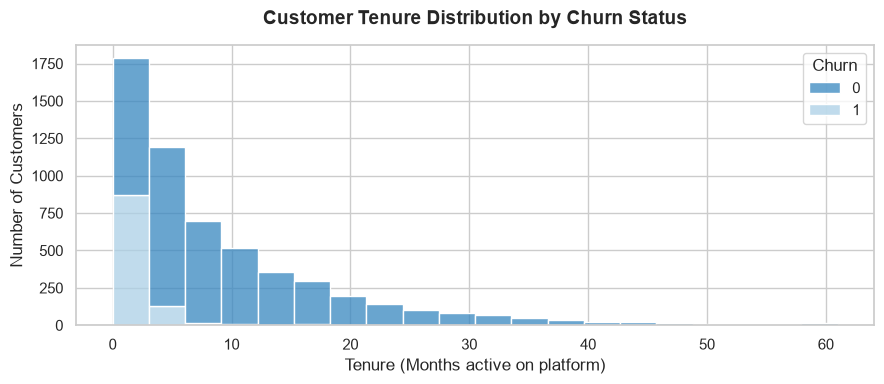

In [15]:
plt.figure(figsize=(9, 4))

sns.histplot(data=df, x='Tenure', hue='Churn', multiple='stack', palette='Blues_r', bins=20)

plt.title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure (Months active on platform)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

plt.tight_layout()
plt.show()

In [16]:
df[df['Tenure'] <= 1]['Churn'].value_counts()

Churn
1    782
0    220
Name: count, dtype: int64


* New Customers (Tenure <= 1 month): 782 customers left, while only 220 stayed.
* High Vulnerability Window: This represents a massive 78% churn rate for users in their first month on the platform.
* Main Takeaway: The vast majority of company churn happens immediately at onboard

In [19]:
df.columns

Index(['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier',
       'WarehouseToHome', 'PreferredPaymentMethod', 'Gender', 'HourSpentOnApp',
       'NumberOfDeviceRegistered', 'SatisfactionScore', 'MaritalStatus',
       'NumberOfAddress', 'Complain', 'OrderAmountHikeFromLastYear',
       'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount'],
      dtype='str')

In [17]:
df['PreferredPaymentMethod'].value_counts()

PreferredPaymentMethod
Debit Card     2280
Credit Card    1685
E Wallet        825
UPI             560
COD             280
Name: count, dtype: int64

• Debit Card: 2,280 accounts
• Credit Card: 1,685 accounts
• E Wallet: 825 accounts
• UPI: 560 accounts
• COD (Cash on Delivery): 280 accounts


In [18]:
pd.crosstab(df['PreferredPaymentMethod'], df['Churn'], normalize='index') * 100

Churn,0,1
PreferredPaymentMethod,,
COD,86.428571,13.571429
Credit Card,81.008902,18.991098
Debit Card,81.798246,18.201754
E Wallet,80.606061,19.393939
UPI,79.464286,20.535714


Looking closely at column 1 (the percentage of users who left), we can see a clear ranking of churn rates by payment method:
• UPI: 20.54% churned (Highest risk)
• E Wallet: 19.39% churned
• Credit Card: 18.99% churned
• Debit Card: 18.20% churned
• COD (Cash on Delivery): 13.57% churned (Lowest risk)

The Business Insight

UPI payments show the highest customer attrition rate at 20.54%.

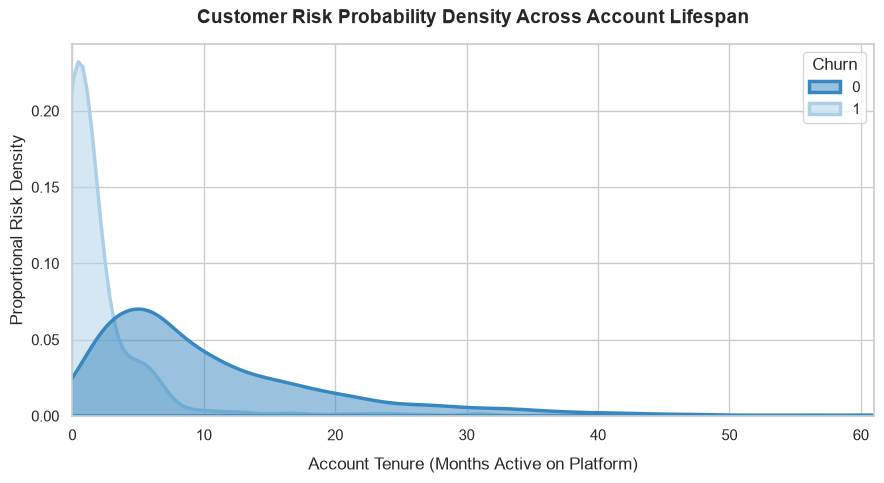

In [19]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

sns.kdeplot(data=df, x='Tenure', hue='Churn', fill=True, common_norm=False, palette='Blues_r', alpha=0.5, linewidth=2.5)

plt.title('Customer Risk Probability Density Across Account Lifespan', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Account Tenure (Months Active on Platform)', fontsize=12, labelpad=10)
plt.ylabel('Proportional Risk Density', fontsize=12)

plt.xlim(0, df['Tenure'].max())
plt.tight_layout()
plt.show()




* Visual Finding: Churned customers (light blue) show a massive risk concentration spike between 0 and 2 months of tenure.
* Visual Drop-off: The attrition curve plummets sharply to near-zero after month 5.
* Business Interpretation: This confirms that if a customer survives their first 90 days on the platform, they are highly unlikely to ever churn. The critical battleground for retention is the onboarding week.

 Business Recommendation 1: The 90-Day Early Habituation Track
* **The Data Rationale:** Our tenure distribution density curve proved that a massive 78% churn rate occurs within a customer's first 30 days on the platform.
* **Action Plan:** The marketing team must launch an automated "Onboarding Habituation Track." This includes a mandatory welcome coupon pack triggered immediately at account creation, coupled with a series of 3 personalized push notifications over the first 14 days to incentivize their second and third orders.

Business Recommendation 2: Priority Resolution Filter for High-Risk Accounts
* **The Data Rationale:** Our cross-tabulation table proved that filing a complaint increases a customer's likelihood of leaving the platform to 26.12%.
* **Action Plan:** The Customer Support team must install an automated "Priority Resolution Filter" inside their CRM software. Any complaint filed by a new customer (tenure under 2 months) who logs a complaint must be instantly escalated to a premium support team for a guaranteed resolution within 12 hours to prevent account abandonment.

Business Recommendation 3: Zone-Based Logistics Optimization
* **The Data Rationale:** Our statistical summary showed that churned users have a significantly higher concentration of long-distance deliveries stretching past 21 km.
* **Action Plan:** The operations team should implement "Zone-Based Fulfillment Adjustments." For outer delivery zones (distances >20 km), the company should partner with premium regional third-party logistics (3PL) carriers to ensure faster dispatch times and provide customers with live GPS transit tracking to minimize arrival anxiety.

Business Recommendation 4: Payment Gateway API Optimization for UPI Checkouts
* **The Data Rationale:** Our transaction cross-tabulation proved that UPI checkouts experience the highest individual churn risk at 20.54%.
* **Action Plan:** The engineering team must review the payment gateway APIs. They should implement an automated network retry mechanism for failed UPI requests, integrate direct in-app bank handles, and offer an immediate backup prompt (like shifting to "Cash on Delivery") if a transaction fails to prevent shopping cart abandonment.